# 08 - K-Nearest Neighbors (KNN)

**Project:** DetectIt – Intelligent Web Threat Detection Using Machine Learning

**Goal:** Train and evaluate the model on the processed PhiUSIIL data, compare different feature sets, and test the URL-only version on the external dataset.

**About the model:** KNN does not build rules. To check a new URL, it finds the K most similar URLs in the training set (its "nearest neighbours") and gives the URL the label that most of them have. Because it measures distances between URLs, all features must be on a similar scale, so we use the shared scaling pipeline.

**Input:** `data/processed/`

**Output:** `results/metrics/`, `results/confusion_matrices/`

## Setup

We load the libraries and the shared functions from `src/`. Every team member uses the same functions, so all results are calculated in the same way and can be compared fairly.

In [1]:
import sys
import time
from pathlib import Path

import pandas as pd
from sklearn.base import clone
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

sys.path.append(str(Path("..").resolve()))
from src.data import get_feature_sets, load_train_test, sample_rows
from src.evaluation import (
    RANDOM_STATE,
    cross_validate_model,
    evaluate_model,
    make_cv,
    make_scaled_pipeline,
    plot_confusion_matrix,
    save_results,
)

In [2]:
X_train, X_test, y_train, y_test = load_train_test()
feature_sets = get_feature_sets()

print(f"Training set: {X_train.shape[0]:,} rows | {X_train.shape[1]} features")
print(f"Test set:     {X_test.shape[0]:,} rows | {X_test.shape[1]} features")

Training set: 187,363 rows | 69 features
Test set:     46,841 rows | 69 features


## Model Settings

We try different numbers of neighbours (K) and two ways of voting: every neighbour has the same vote (`uniform`), or closer neighbours have a bigger vote (`distance`). That gives 8 combinations. KNN is slow on large data, because it compares each URL with every training URL, so we tune on a sample of 30,000 rows. The final model is still trained on the full training set.

In [3]:

MODEL_NAME = "KNN"

model = make_scaled_pipeline(
    KNeighborsClassifier(n_jobs=-1)
)

param_grid = {
    "kneighborsclassifier__n_neighbors": [3, 5, 7, 11],
    "kneighborsclassifier__weights": ["uniform", "distance"],
}

TUNING_SAMPLE_SIZE = 30000


## 1. Hyperparameter Tuning

We try each combination of settings in `param_grid` using 3-fold cross-validation on the training set, and keep the one with the best F1-score. The test set is not used here.

In [4]:
X_tune, y_tune = sample_rows(X_train, y_train, TUNING_SAMPLE_SIZE)

search = GridSearchCV(model, param_grid, scoring="f1", cv=make_cv(3), n_jobs=-1)
search.fit(X_tune, y_tune)
best_model = search.best_estimator_

print(f"Best settings: {search.best_params_}")
print(f"Best cross-validation F1: {search.best_score_:.4f}")

Best settings: {'kneighborsclassifier__n_neighbors': 5, 'kneighborsclassifier__weights': 'distance'}
Best cross-validation F1: 0.9980


## 2. Cross-Validation

We check the best model with 5-fold stratified cross-validation. The mean shows the usual score, and the standard deviation (Std) shows how stable the model is. A small Std means the model gives similar results on different parts of the data.

In [5]:
cv_results = cross_validate_model(best_model, X_tune, y_tune)
cv_results.round(4)

,Mean,Std
Accuracy,0.9982,0.0007
Precision,0.9999,0.0002
Recall,0.9958,0.0015
F1,0.9979,0.0008
ROC-AUC,0.9994,0.0005


### Learning Curve

A learning curve shows how the score changes when the model gets more training data. We use the best settings from tuning and 5-fold cross-validation on a sample of 50,000 training rows.

- **Training F1:** the score on the data the model was trained on.
- **Validation F1:** the score on data the model did not see.

How we read it (at the last point):

- **Overfitting:** the gap (training F1 − validation F1) is more than 0.01. The model memorises the training data.
- **Underfitting:** validation F1 is below 0.95 and the gap is small. The model is too simple to learn the pattern.
- **Good fit:** both lines are high and close together.

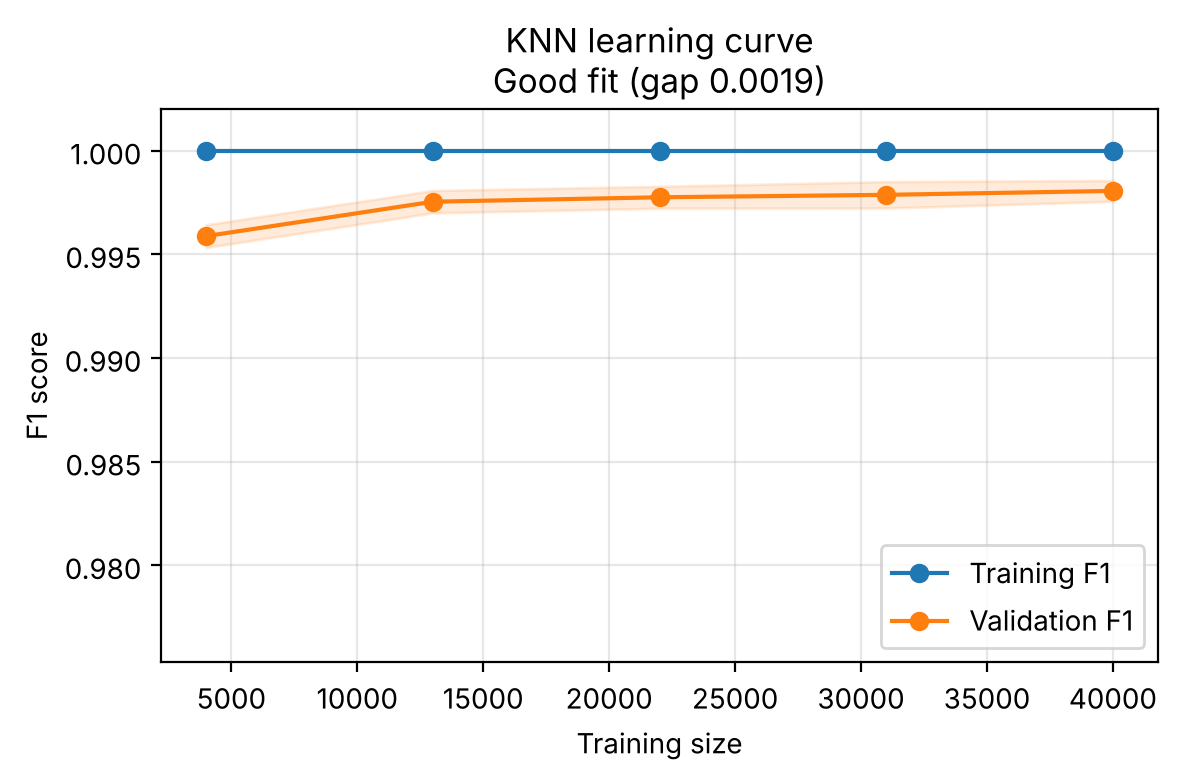

Result: Good fit (gap 0.0019)


,Training size,Training F1,Training Std,Validation F1,Validation Std
0,4000,1.0,0.0,0.9959,0.0005
1,13000,1.0,0.0,0.9975,0.0005
2,22000,1.0,0.0,0.9978,0.0005
3,31000,1.0,0.0,0.9979,0.0006
4,40000,1.0,0.0,0.9981,0.0005


In [ ]:
from src.evaluation import describe_fit, learning_curve_table, plot_learning_curve

X_curve, y_curve = sample_rows(X_train, y_train, 50000)
curve = learning_curve_table(best_model, X_curve, y_curve)
plot_learning_curve(curve, f"{MODEL_NAME} learning curve")

fit, gap = describe_fit(curve)
print(f"Result: {fit} (gap {gap:.4f})")
curve.round(4)

**Result: Good fit.**

- Training F1 is 1.0000 and validation F1 is 0.9981 at the last point. The gap is 0.0019, the biggest of our models, but still below our limit of 0.01.
- Training F1 is always 1.0, because with distance weights every training URL is its own closest neighbour.
- The validation F1 slowly goes up as we add more data, so more training data helps KNN a little. This matches its 39 test mistakes, the most of the supervised models.

## 3. Final Test

We train the best model on the full training set and test it once on the test set. This is the score we report for this model.

In [6]:
start = time.perf_counter()
final_model = clone(best_model).fit(X_train, y_train)
train_time = time.perf_counter() - start

test_results = evaluate_model(final_model, X_test, y_test)
print(f"Training time: {train_time:.1f} seconds")
pd.Series(test_results).round(4).to_frame("Test Score")

Training time: 0.3 seconds


,Test Score
Accuracy,0.9992
Precision,0.9997
Recall,0.9983
F1,0.9990
ROC-AUC,0.9998


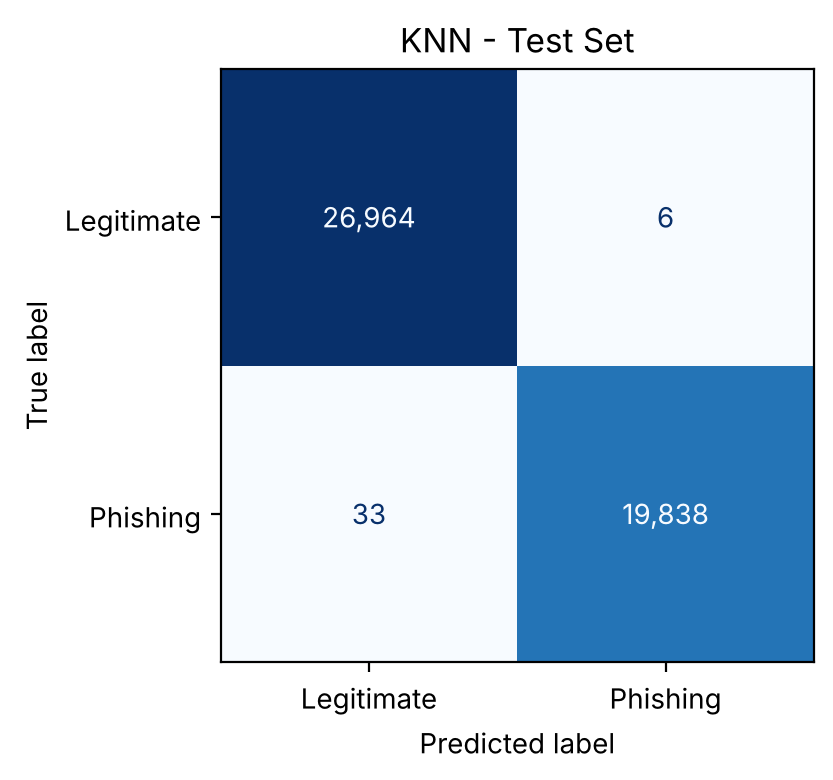

In [7]:
plot_confusion_matrix(y_test, final_model.predict(X_test), f"{MODEL_NAME} - Test Set")

## 4. Feature Set Comparison

We train the same model on two smaller feature sets to answer two questions:

- **Original features only:** do our new features from feature engineering improve the model?
- **Without `URLSimilarityIndex`:** does the model still work well without its strongest feature?

In [8]:
feature_results = {"All features": test_results}

for set_name in ["Original features only", "Without URLSimilarityIndex"]:
    features = feature_sets[set_name]
    set_model = clone(best_model).fit(X_train[features], y_train)
    feature_results[set_name] = evaluate_model(set_model, X_test[features], y_test)

pd.DataFrame(feature_results).T.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
All features,0.9992,0.9997,0.9983,0.9990,0.9998
Original features only,0.9994,0.9998,0.9987,0.9993,0.9997
Without URLSimilarityIndex,0.9991,0.9996,0.9983,0.9990,0.9998


## 5. Save the Results

We save all results in one table. The comparison notebook will later load the tables of all models.

In [9]:
results = [
    {"Experiment": "Cross-validation", **cv_results["Mean"].to_dict()},
    {"Experiment": "Test set - All features", **test_results, "Train Time (s)": train_time},
    {"Experiment": "Test set - Original features only", **feature_results["Original features only"]},
    {"Experiment": "Test set - Without URLSimilarityIndex", **feature_results["Without URLSimilarityIndex"]},
]

save_results(MODEL_NAME, results).round(4)

,Model,Experiment,Accuracy,Precision,Recall,F1,ROC-AUC,Train Time (s)
0,KNN,Cross-validation,0.9982,0.9999,0.9958,0.9979,0.9994,NaN
1,KNN,Test set - All features,0.9992,0.9997,0.9983,0.9990,0.9998,0.288
2,KNN,Test set - Original features only,0.9994,0.9998,0.9987,0.9993,0.9997,NaN
3,KNN,Test set - Without URLSimilarityIndex,0.9991,0.9996,0.9983,0.9990,0.9998,NaN


## 6. Findings

- **Test score:** KNN made **39 mistakes out of 46,841 test URLs** (accuracy 99.92%). It called only 6 legitimate URLs phishing (precision 99.97%) and missed 33 of the 19,871 phishing URLs (recall 99.83%). The F1-score is 0.9990 and the ROC-AUC 0.9998.
- **Best settings:** `n_neighbors = 5` and `weights = "distance"`. With distance weighting, closer neighbours get a bigger vote, which works better than giving all 5 neighbours the same vote.
- **Stability:** The 5-fold cross-validation F1 was 0.9979 ± 0.0008, so the result is stable. The test F1 (0.9990) is a little higher, because tuning and cross-validation used a sample of 30,000 URLs, while the final model uses all 187,363 training URLs. With more training URLs, KNN has closer neighbours to compare with.
- **New features:** With only the original features, KNN made 28 mistakes instead of 39. Our new features did not help KNN. KNN treats every feature as equally important when it measures distance, so extra features that add little information can make the distances less useful.
- **Without `URLSimilarityIndex`:** KNN made 41 mistakes instead of 39, so it does not depend on this one feature.
- **Speed:** Training took only 0.3 seconds, because KNN only stores the training data. But predicting is slow, because every new URL is compared with all training URLs. This makes KNN the slowest of our models when it has to check many URLs.
- **Compared with the other models:** KNN made the most mistakes of the 7 supervised models (Random Forest and Decision Tree made 0), but 99.92% accuracy is still very high.